# FM 2270 Financial Modeling: Risk-Balanced (Inverse-Volatility) Portfolio

**Moodle group:** [MOODLE GROUP NAME]
**Members:** [Full name, student number]
**GitHub repository:** https://github.com/joaojleitao/FM2270_Group_Project
**Streamlit app:** [STREAMLIT APP URL]

This notebook reproduces **every number, table and figure** in the investor prospectus. It runs from start to finish
in a fresh Google Colab session and downloads all data through APIs (no data files).

**Setup instructions**
1. Open https://colab.research.google.com → *File → Upload notebook* (or *Open notebook → GitHub* and paste the repository URL).
2. *Runtime → Run all*. The first code cell installs `yfinance`; everything else is preinstalled in Colab.
3. The data come from Yahoo Finance (prices) and FRED (risk-free rate). Both are free and keyless. The start and end dates
   are fixed in the Parameters cell, so the results are reproducible (Yahoo occasionally revises adjusted prices
   by tiny amounts; see Section 4).
4. Figures and tables are also saved to the folder `outputs/` (used to typeset the prospectus).

**Generative-AI disclosure.** Claude Code (Anthropic, model Claude Opus 5.5) was used for coding, for drafting text and
for checking the class conventions; OpenAI Codex was used as an independent code reviewer. Every output was checked by
running the code, by an independent day-by-day re-implementation of the backtest, and against the course formula sheet
and lecture notebooks. The inverse-volatility strategy was chosen by the group. Full log: `AI_USE_LOG.md` in the repository.

## 1. Setup

In [1]:
# Colab: install what is not preinstalled (quiet). yfinance downloads Yahoo Finance data.
!pip -q install yfinance


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
os.makedirs("outputs", exist_ok=True)          # figures and tables for the prospectus

## 2. Parameters
Every assumption is set here, explicitly. Monthly metrics: means ×12, volatilities ×√12. Beta is not annualized.

In [3]:
DATA_START = '2004-12-01'      # first day of price data (GLD has traded since 18 Nov 2004)
FIRST_DECISION = '2005-12-30'  # first rebalance date (last trading day of 2005): first weights apply from 3 Jan 2006
END_DATE = '2026-10-31'        # last day of data (last complete month when the project was run); inclusive
TICKERS = ['SPY', 'IEF', 'GLD']  # US equities, 7-10 year US Treasuries, gold
LOOKBACK = 252                 # trading days of daily returns used to estimate volatility (about 12 months)
REBALANCE_FREQ = 'M'           # 'M' = monthly, 'Q' = quarterly
COST_BPS = 10                  # transaction cost in basis points on every unit traded: cost = 0.0010 x sum|delta w|
RF_SERIES = 'TB3MS'            # FRED: 3-month Treasury bill, secondary market rate, monthly, % per year
PERIODS_PER_YEAR = 12          # monthly returns -> mean x12, volatility x sqrt(12)
PRIMARY_BENCHMARK = {'SPY': 0.6, 'IEF': 0.4}               # 60/40 stocks/bonds, rebalanced monthly
EQUAL_WEIGHT = {'SPY': 1/3, 'IEF': 1/3, 'GLD': 1/3}         # 1/n of the same three assets, rebalanced monthly

## 3. Calculation functions
These functions are **identical** to `app/strategy.py`, which the Streamlit app uses
(`tests/test_consistency.py` in the repository checks that the code and the results match).

In [4]:
def download_prices(tickers, start, end):
    """Daily adjusted close prices from Yahoo Finance (yfinance, auto_adjust=True).

    `end` is inclusive here (yfinance's own `end` is exclusive, so we add one day).
    Fails loudly if a ticker is missing or the history is too short.
    """
    import yfinance as yf
    end_exclusive = (pd.Timestamp(end) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    data = yf.download(tickers, start=start, end=end_exclusive, interval="1d",
                       auto_adjust=True, progress=False)
    prices = data["Close"][tickers]                       # keep the ticker order we asked for
    prices.index = pd.to_datetime(prices.index).tz_localize(None)
    for t in tickers:                                     # check every ticker has data
        if prices[t].dropna().empty:
            raise ValueError(f"No data downloaded for {t}. Check the ticker or retry (Yahoo can rate-limit).")
    if prices.index[0] > pd.Timestamp(start) + pd.Timedelta(days=10):
        raise ValueError(f"Data starts on {prices.index[0].date()}, later than the requested {start}.")
    return prices

In [5]:
def download_rf(series, start, end):
    """Monthly risk-free rate from FRED (keyless CSV, as in Lecture 3).

    Returns the monthly LOG risk-free return, ln(1 + rate/100)/12, indexed by month (Period 'M').
    """
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}"
    raw = pd.read_csv(url, index_col=0, parse_dates=True)
    rate = pd.to_numeric(raw.iloc[:, 0], errors="coerce")        # % per year; '.' = missing -> NaN
    rate = rate.loc[start:end].dropna()
    rate.index = rate.index.to_period("M")
    return np.log(1 + rate / 100) / 12

In [6]:
def rebalance_dates(daily_returns, freq):
    """Last trading day of each month ('M') or of each quarter ('Q') in the return data."""
    dates = daily_returns.index.to_series()
    return pd.DatetimeIndex(dates.groupby(dates.index.to_period(freq)).last().values)

In [7]:
def inverse_vol_weights(daily_returns, rebalance_dates, lookback_days):
    """Inverse-volatility weights at each rebalance date.

    For each date t in rebalance_dates: sigma_i = std of asset i's daily returns over the
    trailing lookback_days up to and including t, annualized by sqrt(252);
    w_i = (1/sigma_i) / sum_j (1/sigma_j).
    Dates without a full lookback window are skipped.
    Returns a DataFrame (index = rebalance dates, columns = assets). Weights decided at t are
    applied ONLY from the first trading day after t (see backtest).
    """
    rows = {}
    for t in rebalance_dates:
        window = daily_returns.loc[:t].tail(lookback_days)    # only data up to and including t
        if len(window) < lookback_days or window.isna().any().any():
            continue                                          # not enough history yet
        sigma = window.std() * np.sqrt(252)                   # annualized volatility of each asset
        inv = 1 / sigma
        rows[t] = inv / inv.sum()                             # weights sum to 1
    return pd.DataFrame(rows).T

In [8]:
def fixed_weights(rebalance_dates, weights):
    """Benchmark target weights: the same weights (a dict ticker -> weight) at every rebalance date."""
    return pd.DataFrame([weights] * len(rebalance_dates), index=rebalance_dates)

In [9]:
def backtest(daily_returns, target_weights, cost_bps):
    """Run the portfolio through time with rebalancing to target_weights and proportional costs.

    - Starts in cash at the first rebalance date t0 and buys the target weights (this first trade pays costs too).
    - Weights decided at the close of rebalance date t earn returns from the first trading day after t.
    - Between rebalances the holdings drift with prices (buy-and-hold inside the period).
    - Cost at each rebalance = cost_bps/10,000 x sum_i |target_i - drifted_i| (every unit bought or sold pays).
    Returns a DataFrame of MONTHLY simple returns (index = month-end trading days) with columns:
    gross (before costs), net (after costs) and turnover (sum |delta w| traded in that month).
    """
    c = cost_bps / 10_000
    assets = target_weights.columns
    rets = daily_returns[assets]
    dates = list(target_weights.index)
    held = pd.Series(0.0, index=assets)        # weights held just before trading (start in cash)
    gross_value, net_value = 1.0, 1.0
    gross_path, net_path, trades = {}, {}, {}
    for k, t in enumerate(dates):
        end = dates[k + 1] if k + 1 < len(dates) else rets.index[-1]
        period = rets.loc[(rets.index > t) & (rets.index <= end)]   # returns AFTER the decision date
        if period.empty:
            continue                                   # last decision date: nothing left to invest in
        target = target_weights.loc[t]
        turnover = (target - held).abs().sum()
        trades[period.index[0]] = turnover             # booked in the month whose return pays the cost
        net_value *= 1 - c * turnover                  # pay costs when trading at t
        growth = (1 + period).cumprod()                # growth of $1 in each asset since t
        port_growth = (growth * target).sum(axis=1)    # growth of the portfolio since t
        for d, g in port_growth.items():
            gross_path[d] = gross_value * g
            net_path[d] = net_value * g
        gross_value *= port_growth.iloc[-1]
        net_value *= port_growth.iloc[-1]
        held = target * growth.iloc[-1] / port_growth.iloc[-1]    # drifted weights at the next rebalance
    daily = pd.DataFrame({"gross": pd.Series(gross_path), "net": pd.Series(net_path)}).sort_index()
    month_end = daily.groupby(daily.index.to_period("M")).tail(1)   # value at each month-end
    monthly = month_end.pct_change()
    monthly.iloc[0] = month_end.iloc[0] - 1.0          # first month: relative to the starting value of 1
    trades = pd.Series(trades)
    turnover = trades.groupby(trades.index.to_period("M")).sum()
    monthly["turnover"] = turnover.reindex(monthly.index.to_period("M")).fillna(0.0).values
    return monthly

In [10]:
def max_drawdown(cumulative):
    """Maximum drawdown of a cumulative index: max_t (HWM_t - P_t) / HWM_t (course formula sheet)."""
    hwm = cumulative.cummax()                          # high-water mark
    return ((hwm - cumulative) / hwm).max()

In [11]:
def performance_table(port_returns, bench_returns, rf, periods_per_year=12):
    """Annualized mean, volatility, Sharpe, alpha, beta (not annualized), information ratio, max drawdown.

    port_returns, bench_returns: monthly SIMPLE returns (same dates). rf: monthly LOG risk-free return
    on the same dates. Returns are converted to log returns (course convention) before the statistics.
    """
    n = periods_per_year
    r = np.log1p(port_returns)                         # monthly log returns
    rb = np.log1p(bench_returns)
    ex, exb = r - rf, rb - rf                          # excess returns over the risk-free rate
    beta = np.cov(ex, exb)[0, 1] / np.var(exb, ddof=1)  # cov / var (not annualized)
    alpha = ex.mean() - beta * exb.mean()              # monthly alpha
    resid = ex - alpha - beta * exb                    # regression residuals (for alpha's t-stat)
    se_alpha = np.sqrt((resid ** 2).sum() / (len(r) - 2)
                       * (1 / len(r) + exb.mean() ** 2 / ((exb - exb.mean()) ** 2).sum()))
    active = r - rb                                    # return relative to the benchmark
    return {
        "Annualized mean return": n * r.mean(),
        "Annualized volatility": np.sqrt(n) * r.std(),
        "Sharpe ratio": n * ex.mean() / (np.sqrt(n) * ex.std()),
        "Beta (not annualized)": beta,
        "Alpha (annualized)": n * alpha,
        "Alpha t-stat": alpha / se_alpha,
        "Tracking error (annualized)": np.sqrt(n) * active.std(),
        "Information ratio": n * active.mean() / (np.sqrt(n) * active.std()),
        "Max drawdown": max_drawdown(np.exp(r.cumsum())),
    }

## 4. Data download via API, and the four checks
* **Prices:** Yahoo Finance through `yfinance`, daily, `auto_adjust=True`: closes adjusted for splits **and dividends**,
  so returns are total returns. ETF expense ratios are already deducted in the ETF prices.
* **Risk-free rate:** FRED series TB3MS (3-month T-bill, monthly average, % p.a.), keyless CSV as in Lecture 3.
  Monthly log rate = ln(1 + TB3MS/100)/12. TB3MS is quoted on a discount basis; the difference from a bond-equivalent
  yield is a few basis points per year and is ignored.

Checks (Lecture 3): shape, date range, missing values and a plot.

1) Shape: (5514, 3)
2) Date range: 2004-12-01 to 2026-10-30
3) Missing values per ticker: {'SPY': 0, 'IEF': 0, 'GLD': 0}
   Risk-free months: 263 from 2004-12 to 2026-10 | missing: 0


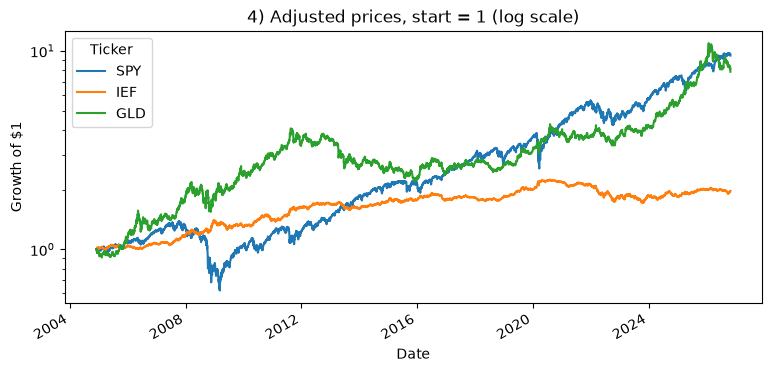

In [12]:
prices = download_prices(TICKERS, DATA_START, END_DATE)
rf_monthly = download_rf(RF_SERIES, DATA_START, END_DATE)

print('1) Shape:', prices.shape)
print('2) Date range:', prices.index[0].date(), 'to', prices.index[-1].date())
print('3) Missing values per ticker:', prices.isna().sum().to_dict())
print('   Risk-free months:', len(rf_monthly), 'from', rf_monthly.index[0], 'to', rf_monthly.index[-1],
      '| missing:', int(rf_monthly.isna().sum()))
assert prices.isna().sum().sum() == 0, 'Unexpected missing prices: inspect before continuing'
assert prices.index[-1] >= pd.Timestamp(END_DATE) - pd.Timedelta(days=5), 'Price data end too early'

ax = (prices / prices.iloc[0]).plot(figsize=(9, 4), logy=True, title='4) Adjusted prices, start = 1 (log scale)')
ax.set_ylabel('Growth of $1'); plt.show()

## 5. Data adjustments
* Daily **simple** returns from adjusted prices; the first day is dropped (no return).
* All three ETFs trade on the same US calendar, so no alignment across assets is needed (checked above: no missing values).
* No outliers are removed: large moves (2008, March 2020) are real and part of the risk the client bears.
* The risk-free rate is monthly and is matched to each month of portfolio returns.
* Portfolio returns are aggregated from simple returns (exact). Performance measures use monthly **log** returns
  (course convention): log return = ln(1 + simple return).

In [13]:
daily_returns = prices.pct_change().iloc[1:]
print(daily_returns.describe().loc[['count', 'mean', 'std', 'min', 'max']])

Ticker        SPY        IEF        GLD
count  5,513.0000 5,513.0000 5,513.0000
mean       0.0005     0.0001     0.0004
std        0.0119     0.0042     0.0115
min       -0.1094    -0.0251    -0.1027
max        0.1452     0.0343     0.1129


## 6. Strategy: inverse-volatility weights
At each month-end *t*: σ(i,t) = standard deviation of asset *i*'s daily returns over the last 252 trading days
**up to and including t** (annualized ×√252), and w(i,t) = (1/σ(i,t)) / Σⱼ (1/σ(j,t)).
The weights are applied only to returns from the **first trading day of month t+1** (no look-ahead).
Between rebalances the holdings drift with prices.

*Inverse volatility is not full risk parity: it ignores correlations, so each asset's contribution to total
portfolio risk is only approximately equal.*

        Average    Min    Max  Latest (2026-10-30)
Ticker                                            
SPY      0.2245 0.1349 0.3122               0.2482
IEF      0.5602 0.4063 0.6806               0.6405
GLD      0.2153 0.1047 0.3243               0.1113


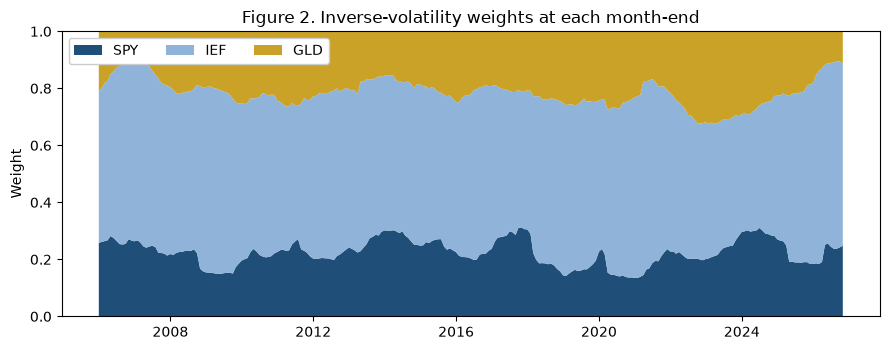

In [14]:
all_dates = rebalance_dates(daily_returns, REBALANCE_FREQ)
decision_dates = all_dates[all_dates >= FIRST_DECISION]
weights = inverse_vol_weights(daily_returns, decision_dates, LOOKBACK)
assert weights.index[0] == pd.Timestamp(FIRST_DECISION), 'First decision date lacks a full lookback window'
assert np.allclose(weights.sum(axis=1), 1.0)

# look-ahead check: recompute one date using ONLY data up to that date
t_check = weights.index[len(weights) // 2]          # a date in the middle of the sample
w_check = inverse_vol_weights(daily_returns.loc[:t_check], [t_check], LOOKBACK)
assert np.allclose(w_check.loc[t_check], weights.loc[t_check]), 'Weights use future data!'

weight_stats = pd.DataFrame({'Average': weights.mean(), 'Min': weights.min(), 'Max': weights.max(),
                             'Latest (' + str(weights.index[-1].date()) + ')': weights.iloc[-1]})
print(weight_stats)
weight_stats.to_csv('outputs/weight_stats.csv')

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.stackplot(weights.index, weights.T.values, labels=weights.columns, colors=['#1f4e79', '#8fb3d9', '#c9a227'])
ax.set_ylim(0, 1); ax.set_ylabel('Weight'); ax.legend(loc='upper left', ncol=3, frameon=True, framealpha=1)
ax.set_title('Figure 2. Inverse-volatility weights at each month-end')
fig.tight_layout(); fig.savefig('outputs/fig2_weights.png', dpi=200); plt.show()

## 7. Backtest: strategy and benchmarks
* **Strategy:** inverse-volatility, monthly rebalancing, 10 bps on every unit traded.
* **Primary benchmark: 60/40 SPY/IEF**, rebalanced monthly: the classic moderate portfolio for the same client.
* **Secondary benchmark: equal weight (1/3 each) of SPY, IEF, GLD**, rebalanced monthly: same assets, naive weights.
  It separates the effect of *adding gold* from the effect of *inverse-volatility weighting*.
* **Context: SPY**, buy and hold.

All portfolios start in cash on 30 Dec 2005, pay the same costs (including the first purchase), and are evaluated
over the same months (January 2006 to October 2026).

In [15]:
strategy = backtest(daily_returns, weights, COST_BPS)
bench_6040 = backtest(daily_returns, fixed_weights(decision_dates, PRIMARY_BENCHMARK), COST_BPS)
bench_ew = backtest(daily_returns, fixed_weights(decision_dates, EQUAL_WEIGHT), COST_BPS)
bench_spy = backtest(daily_returns, fixed_weights(decision_dates[:1], {'SPY': 1.0}), COST_BPS)

# risk-free rate on the same months as the portfolio returns
rf = rf_monthly.reindex(strategy.index.to_period('M'))
rf.index = strategy.index
assert rf.notna().all(), 'Risk-free rate missing for some months'
assert strategy.index.equals(bench_6040.index) and strategy.index.equals(bench_spy.index)

portfolios = {'Inverse-vol (strategy)': strategy, '60/40 (primary benchmark)': bench_6040,
              'Equal weight 1/3': bench_ew, 'SPY buy & hold': bench_spy}
net = pd.DataFrame({k: v['net'] for k, v in portfolios.items()})
print('Months:', len(net), '| first:', net.index[0].date(), '| last:', net.index[-1].date())
net.head()

Months: 250 | first: 2006-01-31 | last: 2026-10-30


,Inverse-vol (strategy),60/40 (primary benchmark),Equal weight 1/3,SPY buy & hold
2006-01-31,0.0224,0.0106,0.0377,0.0230
2006-02-28,-0.0013,0.0030,-0.0022,0.0057
2006-03-31,0.0033,0.0045,0.0130,0.0165
2006-04-28,0.0207,0.0051,0.0422,0.0126
2006-05-31,-0.0112,-0.0185,-0.0148,-0.0301


## 8. Cumulative performance (all series start at 1)

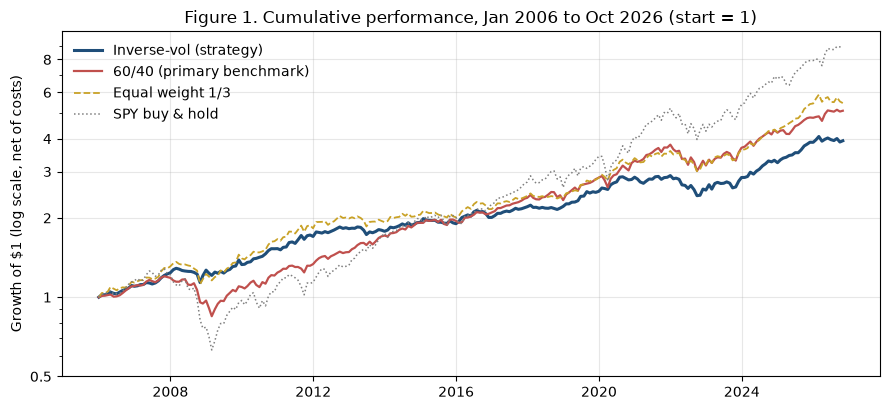

Inverse-vol (strategy)      3.9291
60/40 (primary benchmark)   5.1091
Equal weight 1/3            5.4616
SPY buy & hold              8.8522
Name: Final value of $1, dtype: float64


In [16]:
cumulative = np.exp(np.log1p(net).cumsum())                 # = product of (1 + monthly return)
start_row = pd.DataFrame(1.0, index=[decision_dates[0]], columns=net.columns)
cumulative = pd.concat([start_row, cumulative])             # value 1 on 30 Dec 2005

fig, ax = plt.subplots(figsize=(9, 4.2))
styles = {'Inverse-vol (strategy)': ('#1f4e79', 2.2, '-'), '60/40 (primary benchmark)': ('#c0504d', 1.6, '-'),
          'Equal weight 1/3': ('#c9a227', 1.3, '--'), 'SPY buy & hold': ('#7f7f7f', 1.1, ':')}
for col in cumulative:
    c, lw, ls = styles[col]
    ax.plot(cumulative.index, cumulative[col], color=c, lw=lw, ls=ls, label=col)
ax.set_yscale('log'); ax.set_ylabel('Growth of $1 (log scale, net of costs)')
ax.set_yticks([0.5, 1, 2, 3, 4, 6, 8]); ax.set_yticklabels(['0.5', '1', '2', '3', '4', '6', '8'])
ax.legend(frameon=False); ax.grid(alpha=0.3)
ax.set_title('Figure 1. Cumulative performance, Jan 2006 to Oct 2026 (start = 1)')
fig.tight_layout(); fig.savefig('outputs/fig1_cumulative.png', dpi=200); plt.show()
print(cumulative.iloc[-1].rename('Final value of $1'))

## 9. Performance measures (net of costs, monthly data)
Assumptions: monthly log returns; annualized mean = 12 × mean; annualized volatility = √12 × std;
Sharpe ratio = 12·mean(R − R_f) / (√12·std(R − R_f)); beta and alpha from the excess-return regression on the
**60/40 benchmark's** excess returns, by cov/var as in class (beta **not annualized**; alpha ×12);
information ratio = 12·mean(R − R_b) / (√12·std(R − R_b)) against the 60/40 benchmark (formula sheet version);
maximum drawdown on the cumulative index. Risk-free: FRED TB3MS.

In [17]:
perf = pd.DataFrame({k: performance_table(v['net'], bench_6040['net'], rf, PERIODS_PER_YEAR)
                     for k, v in portfolios.items()})
# the benchmark against itself has no alpha t-stat, tracking error or IR
perf.loc[['Alpha t-stat', 'Tracking error (annualized)', 'Information ratio'], '60/40 (primary benchmark)'] = np.nan
perf = perf.mask(perf.abs() < 1e-12, 0.0)               # benchmark vs itself: alpha is 0 up to rounding
perf.loc['Final value of $1'] = cumulative.iloc[-1]
perf.loc['Average annual turnover'] = {k: v['turnover'].iloc[1:].sum() / (len(v) / 12) for k, v in portfolios.items()}
perf.to_csv('outputs/table1_performance.csv')
perf

C:\Users\João\AppData\Local\Temp\ipykernel_23424\3409279832.py:25: RuntimeWarning: invalid value encountered in scalar divide
  "Information ratio": n * active.mean() / (np.sqrt(n) * active.std()),


,Inverse-vol (strategy),60/40 (primary benchmark),Equal weight 1/3,SPY buy & hold
Annualized mean return,0.0657,0.0783,0.0815,0.1047
Annualized volatility,0.0686,0.0923,0.0871,0.1510
Sharpe ratio,0.7142,0.6644,0.7438,0.5813
Beta (not annualized),0.4817,1.0000,0.6838,1.5657
Alpha (annualized),0.0192,0.0000,0.0226,-0.0083
Alpha t-stat,1.6584,NaN,1.6981,-0.8631
Tracking error (annualized),0.0706,NaN,0.0664,0.0678
Information ratio,-0.1787,NaN,0.0483,0.3889
Max drawdown,0.1612,0.2949,0.1772,0.5078
Final value of $1,3.9291,5.1091,5.4616,8.8522


**Gross versus net of costs.** The cost model charges 10 bps on every unit bought or sold (Lecture 4 model,
cost × |Δposition|). Turnover = Σ|Δw| per rebalance (the first purchase counts as turnover of 1 and is excluded
from the annual average above).

In [18]:
gross_vs_net = pd.DataFrame({
    'Gross mean (ann.)': {k: PERIODS_PER_YEAR * np.log1p(v['gross']).mean() for k, v in portfolios.items()},
    'Net mean (ann.)': {k: PERIODS_PER_YEAR * np.log1p(v['net']).mean() for k, v in portfolios.items()},
})
gross_vs_net['Cost drag (ann.)'] = gross_vs_net['Gross mean (ann.)'] - gross_vs_net['Net mean (ann.)']
gross_vs_net.to_csv('outputs/table_gross_net.csv')
gross_vs_net

,Gross mean (ann.),Net mean (ann.),Cost drag (ann.)
Inverse-vol (strategy),0.0661,0.0657,0.0004
60/40 (primary benchmark),0.0785,0.0783,0.0003
Equal weight 1/3,0.0818,0.0815,0.0003
SPY buy & hold,0.1047,0.1047,0.0000


## 10. Drawdowns and rolling risk

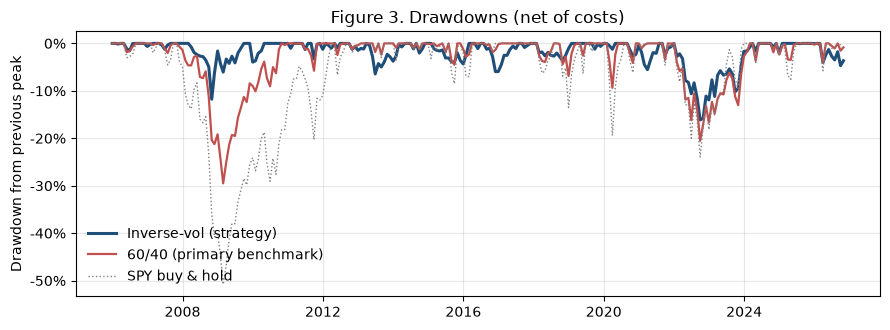

Range of 36-month rolling volatility:
                             min    max
Inverse-vol (strategy)    0.0438 0.0990
60/40 (primary benchmark) 0.0507 0.1385
Equal weight 1/3          0.0533 0.1199
SPY buy & hold            0.0838 0.2256

Calendar-year returns (net):
      Inverse-vol (strategy)  60/40 (primary benchmark)  Equal weight 1/3  \
2006                  0.0999                     0.1026            0.1364   
2007                  0.1252                     0.0740            0.1519   
2008                  0.0236                    -0.1804           -0.0646   
2009                  0.0498                     0.1258            0.1464   
2010                  0.1498                     0.1348            0.1839   
2011                  0.1123                     0.0766            0.0991   
2012                  0.0706                     0.1113            0.0896   
2013                 -0.0229                     0.1557           -0.0319   
2014                  0.0814           

In [19]:
drawdowns = (cumulative.cummax() - cumulative) / cumulative.cummax()
fig, ax = plt.subplots(figsize=(9, 3.4))
for col in ['Inverse-vol (strategy)', '60/40 (primary benchmark)', 'SPY buy & hold']:
    c, lw, ls = styles[col]
    ax.plot(drawdowns.index, -drawdowns[col], color=c, lw=lw if col != 'SPY buy & hold' else 1.0, ls=ls, label=col)
ax.set_ylabel('Drawdown from previous peak'); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.legend(frameon=False, loc='lower left'); ax.grid(alpha=0.3)
ax.set_title('Figure 3. Drawdowns (net of costs)')
fig.tight_layout(); fig.savefig('outputs/fig3_drawdowns.png', dpi=200); plt.show()

# 36-month rolling annualized volatility: is the risk level stable over time?
rolling_vol = np.log1p(net).rolling(36).std() * np.sqrt(PERIODS_PER_YEAR)
print('Range of 36-month rolling volatility:')
print(pd.DataFrame({'min': rolling_vol.min(), 'max': rolling_vol.max()}))
rolling_vol.agg(['min', 'max']).T.to_csv('outputs/rolling_vol_range.csv')

# worst months and calendar years
yearly = np.exp(np.log1p(net).groupby(net.index.year).sum()) - 1
print('\nCalendar-year returns (net):'); print(yearly)
yearly.to_csv('outputs/yearly_returns.csv')

## 11. Robustness checks
Parameters such as the 12-month lookback can be "found" by searching the same history (data snooping, Lecture 4),
so we report how the results change with: the **lookback** (3, 6, 12 months), the **rebalancing frequency**
(monthly vs quarterly), the **cost level** (0, 10, 25, 50 bps), a one-day **execution lag** (Lecture 4's `shift(2)`
idea: trade at the close of the first trading day of the month), and **sub-periods**, including 2022 when stocks and
bonds fell together. All versions are measured over the same months against the 60/40 benchmark.

In [20]:
key_rows = ['Annualized mean return', 'Annualized volatility', 'Sharpe ratio', 'Beta (not annualized)',
            'Alpha (annualized)', 'Information ratio', 'Max drawdown']
robust = {}

def run_variant(lookback=LOOKBACK, freq=REBALANCE_FREQ, cost=COST_BPS):
    dates = rebalance_dates(daily_returns, freq)
    dates = dates[dates >= FIRST_DECISION]
    w = inverse_vol_weights(daily_returns, dates, lookback)
    return backtest(daily_returns, w, cost), w

for months, days in [(3, 63), (6, 126), (12, 252)]:
    bt, _ = run_variant(lookback=days)
    robust[f'Lookback {months}m'] = performance_table(bt['net'], bench_6040['net'], rf)
bt_q, _ = run_variant(freq='Q')
robust['Quarterly rebalancing'] = performance_table(bt_q['net'], bench_6040['net'], rf)

# execution lag: the weights decided at month-end t are traded one trading day later (first day of month t+1)
w_lag = weights.iloc[:-1].copy()
w_lag.index = [daily_returns.index[daily_returns.index.get_loc(t) + 1] for t in w_lag.index]
bt_lag = backtest(daily_returns, w_lag, COST_BPS)
robust['1-day execution lag'] = performance_table(bt_lag['net'], bench_6040['net'], rf)

robust_table = pd.DataFrame(robust).loc[key_rows]
robust_table.to_csv('outputs/table2_robustness.csv')
robust_table

,Lookback 3m,Lookback 6m,Lookback 12m,Quarterly rebalancing,1-day execution lag
Annualized mean return,0.0675,0.0663,0.0657,0.0644,0.0653
Annualized volatility,0.0675,0.0681,0.0686,0.0690,0.0685
Sharpe ratio,0.7524,0.7281,0.7142,0.6912,0.7099
Beta (not annualized),0.4751,0.4791,0.4817,0.4827,0.4799
Alpha (annualized),0.0214,0.0200,0.0192,0.0179,0.0189
Information ratio,-0.1535,-0.1700,-0.1787,-0.1963,-0.1838
Max drawdown,0.1599,0.1597,0.1612,0.1639,0.1605


In [21]:
# cost sensitivity: strategy AND benchmark pay the same cost; Sharpe ratios and alpha
cost_rows = {}
for c in [0, 10, 25, 50]:
    s = backtest(daily_returns, weights, c)
    b = backtest(daily_returns, fixed_weights(decision_dates, PRIMARY_BENCHMARK), c)
    p_s, p_b = performance_table(s['net'], b['net'], rf), performance_table(b['net'], b['net'], rf)
    cost_rows[f'{c} bps'] = {'Strategy mean (ann.)': p_s['Annualized mean return'], 'Strategy Sharpe': p_s['Sharpe ratio'],
                             '60/40 Sharpe': p_b['Sharpe ratio'], 'Alpha (ann.)': p_s['Alpha (annualized)']}
cost_table = pd.DataFrame(cost_rows).T
cost_table.to_csv('outputs/table3_costs.csv')
print(cost_table)

# breakeven cost: the cost (bps per unit traded, paid by both) at which the strategy's Sharpe edge over 60/40 is zero
def sharpe_edge(c):
    s = backtest(daily_returns, weights, c)
    b = backtest(daily_returns, fixed_weights(decision_dates, PRIMARY_BENCHMARK), c)
    return performance_table(s['net'], b['net'], rf)['Sharpe ratio'] - performance_table(b['net'], b['net'], rf)['Sharpe ratio']

lo, hi = 0.0, 2000.0
edge_0 = sharpe_edge(lo)
print(f'Sharpe edge over 60/40 at zero cost: {edge_0:.3f}')
if edge_0 <= 0:
    breakeven_bps = 0.0
    print('No positive Sharpe edge even without costs: no breakeven to compute.')
elif sharpe_edge(hi) > 0:
    breakeven_bps = float('inf')
    print('The Sharpe edge survives even 2,000 bps per unit traded.')
else:
    # check the edge falls steadily with costs on a coarse grid, so the bisection finds the single crossing
    grid = [sharpe_edge(c) for c in range(0, 2001, 250)]
    assert all(a > b for a, b in zip(grid, grid[1:])), 'Sharpe edge is not monotone in costs'
    for _ in range(30):                     # bisection
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if sharpe_edge(mid) > 0 else (lo, mid)
    breakeven_bps = (lo + hi) / 2
    print(f'Breakeven cost (Sharpe edge over 60/40 = 0): {breakeven_bps:,.0f} bps per unit traded')

C:\Users\João\AppData\Local\Temp\ipykernel_23424\3409279832.py:25: RuntimeWarning: invalid value encountered in scalar divide
  "Information ratio": n * active.mean() / (np.sqrt(n) * active.std()),


C:\Users\João\AppData\Local\Temp\ipykernel_23424\3409279832.py:25: RuntimeWarning: invalid value encountered in scalar divide
  "Information ratio": n * active.mean() / (np.sqrt(n) * active.std()),


C:\Users\João\AppData\Local\Temp\ipykernel_23424\3409279832.py:23: RuntimeWarning: invalid value encountered in scalar divide
  "Alpha t-stat": alpha / se_alpha,
C:\Users\João\AppData\Local\Temp\ipykernel_23424\3409279832.py:25: RuntimeWarning: invalid value encountered in scalar divide
  "Information ratio": n * active.mean() / (np.sqrt(n) * active.std()),


C:\Users\João\AppData\Local\Temp\ipykernel_23424\3409279832.py:25: RuntimeWarning: invalid value encountered in scalar divide
  "Information ratio": n * active.mean() / (np.sqrt(n) * active.std()),


        Strategy mean (ann.)  Strategy Sharpe  60/40 Sharpe  Alpha (ann.)
0 bps                 0.0661           0.7195        0.6672        0.0195
10 bps                0.0657           0.7142        0.6644        0.0192
25 bps                0.0651           0.7061        0.6603        0.0188
50 bps                0.0642           0.6927        0.6533        0.0182


C:\Users\João\AppData\Local\Temp\ipykernel_23424\3409279832.py:25: RuntimeWarning: invalid value encountered in scalar divide
  "Information ratio": n * active.mean() / (np.sqrt(n) * active.std()),


... (38 outputs left out)

C:\Users\João\AppData\Local\Temp\ipykernel_23424\3409279832.py:23: RuntimeWarning: invalid value encountered in scalar divide
  "Alpha t-stat": alpha / se_alpha,
C:\Users\João\AppData\Local\Temp\ipykernel_23424\3409279832.py:25: RuntimeWarning: invalid value encountered in scalar divide
  "Information ratio": n * active.mean() / (np.sqrt(n) * active.std()),


C:\Users\João\AppData\Local\Temp\ipykernel_23424\3409279832.py:23: RuntimeWarning: invalid value encountered in scalar divide
  "Alpha t-stat": alpha / se_alpha,
C:\Users\João\AppData\Local\Temp\ipykernel_23424\3409279832.py:25: RuntimeWarning: invalid value encountered in scalar divide
  "Information ratio": n * active.mean() / (np.sqrt(n) * active.std()),


Breakeven cost (Sharpe edge over 60/40 = 0): 199 bps per unit traded


C:\Users\João\AppData\Local\Temp\ipykernel_23424\3409279832.py:25: RuntimeWarning: invalid value encountered in scalar divide
  "Information ratio": n * active.mean() / (np.sqrt(n) * active.std()),


In [22]:
# sub-periods: SEGMENTS of the one continuous backtest (weights and holdings carried in from before each
# segment; drawdowns measured within the segment). 2022 = stocks and bonds fell together
periods = {'2006-2015': ('2006-01', '2015-12'), '2016-Oct 2026': ('2016-01', '2026-10'), '2022 only': ('2022-01', '2022-12'),
           '2008 only': ('2008-01', '2008-12')}
sub = {}
for label, (a, b) in periods.items():
    for name in ['Inverse-vol (strategy)', '60/40 (primary benchmark)', 'Equal weight 1/3']:
        p = performance_table(net.loc[a:b, name], net.loc[a:b, '60/40 (primary benchmark)'], rf.loc[a:b])
        sub[(label, name)] = {'Mean (ann.)': p['Annualized mean return'], 'Volatility (ann.)': p['Annualized volatility'],
                              'Sharpe': p['Sharpe ratio'], 'Max drawdown': p['Max drawdown']}
sub_table = pd.DataFrame(sub).T
sub_table.to_csv('outputs/table4_subperiods.csv')
sub_table

C:\Users\João\AppData\Local\Temp\ipykernel_23424\3409279832.py:25: RuntimeWarning: invalid value encountered in scalar divide
  "Information ratio": n * active.mean() / (np.sqrt(n) * active.std()),
C:\Users\João\AppData\Local\Temp\ipykernel_23424\3409279832.py:23: RuntimeWarning: invalid value encountered in scalar divide
  "Alpha t-stat": alpha / se_alpha,


Mean (ann.)  Volatility (ann.)  \
2006-2015     Inverse-vol (strategy)          0.0643             0.0658   
              60/40 (primary benchmark)       0.0667             0.0871   
              Equal weight 1/3                0.0698             0.0877   
2016-Oct 2026 Inverse-vol (strategy)          0.0670             0.0713   
              60/40 (primary benchmark)       0.0890             0.0971   
              Equal weight 1/3                0.0922             0.0869   
2022 only     Inverse-vol (strategy)         -0.1269             0.1065   
              60/40 (primary benchmark)      -0.1824             0.1651   
              Equal weight 1/3               -0.1186             0.1207   
2008 only     Inverse-vol (strategy)          0.0233             0.1189   
              60/40 (primary benchmark)      -0.1989             0.1325   
              Equal weight 1/3               -0.0668             0.1469   

                                         Sharpe  Max drawdown  
2006-2015     Inverse-vol (strategy)     0.8137        0.1177  
              60/40 (primary benchmark)  0.6393        0.2949  
              Equal weight 1/3           0.6750        0.1772  
2016-Oct 2026 Inverse-vol (strategy)     0.6274        0.1612  
              60/40 (primary benchmark)  0.6848        0.2052  
              Equal weight 1/3           0.8054        0.1626  
2022 only     Inverse-vol (strategy)    -1.3957        0.1424  
              60/40 (primary benchmark) -1.2326        0.1720  
              Equal weight 1/3          -1.1588        0.1473  
2008 only     Inverse-vol (strategy)     0.0821        0.1177  
              60/40 (primary benchmark) -1.6038        0.1909  
              Equal weight 1/3          -0.5472        0.1772

## 12. Numbers used in the prospectus text

In [23]:
numbers = {
    'first_month': str(net.index[0].date()), 'last_month': str(net.index[-1].date()), 'n_months': len(net),
    'breakeven_bps': breakeven_bps,
    'avg_weights': weights.mean().to_dict(), 'latest_weights': weights.iloc[-1].to_dict(),
    'latest_weight_date': str(weights.index[-1].date()),
    'rolling_vol_min': rolling_vol.min().to_dict(), 'rolling_vol_max': rolling_vol.max().to_dict(),
    'rf_mean_annual': float(PERIODS_PER_YEAR * rf.mean()),
    'corr_spy_ief_2022': float(daily_returns.loc['2022', 'SPY'].corr(daily_returns.loc['2022', 'IEF'])),
    'corr_spy_ief_full': float(daily_returns.loc['2006':, 'SPY'].corr(daily_returns.loc['2006':, 'IEF'])),
    'worst_month': {k: float(net[k].min()) for k in net}, 'worst_month_date': {k: str(net[k].idxmin().date()) for k in net},
}
with open('outputs/numbers.json', 'w') as f:
    json.dump(numbers, f, indent=2, default=float)
print(json.dumps(numbers, indent=2, default=float))

{
  "first_month": "2006-01-31",
  "last_month": "2026-10-30",
  "n_months": 250,
  "breakeven_bps": 199.13053046911955,
  "avg_weights": {
    "SPY": 0.22447796408252504,
    "IEF": 0.5602233183132025,
    "GLD": 0.21529871760427238
  },
  "latest_weights": {
    "SPY": 0.24821143470347184,
    "IEF": 0.640470405719732,
    "GLD": 0.11131815957679614
  },
  "latest_weight_date": "2026-10-30",
  "rolling_vol_min": {
    "Inverse-vol (strategy)": 0.04383586880888779,
    "60/40 (primary benchmark)": 0.05067457048836433,
    "Equal weight 1/3": 0.0533443602011258,
    "SPY buy & hold": 0.08377002511646942
  },
  "rolling_vol_max": {
    "Inverse-vol (strategy)": 0.09898725371951188,
    "60/40 (primary benchmark)": 0.13854145935377943,
    "Equal weight 1/3": 0.11988860081656826,
    "SPY buy & hold": 0.22563916252150193
  },
  "rf_mean_annual": 0.01690107784255022,
  "corr_spy_ief_2022": 0.19001105348122016,
  "corr_spy_ief_full": -0.28743316176157097,
  "worst_month": {
    "Inverse-vo

## 13. Notes on the method and limitations (summarised; discussed in the prospectus)
* **Alpha t-statistic:** conventional OLS standard error (no correction for autocorrelation or heteroskedasticity).
* **Costs of the first purchase** are charged in the first month (January 2006) for every portfolio.
* **Selection / hindsight bias:** the three asset classes were chosen for their economic role, but we know today that
  gold did very well after 2005. The three ETFs still trade today: we test today's chosen ETF proxies, so funds that
  were closed or merged are not part of the choice set (a mild form of survivorship bias). Inside the ETFs, the S&P 500
  index itself replaces failing companies, which is part of the investable index return and not a backtest bias.
* **Correlations are ignored** (not full risk parity). In 2022 bonds did not hedge stocks.
* **USD results.** A euro investor also bears EUR/USD risk unless a hedged share class is used; taxes are ignored.
* **Execution:** trading at the month-end close is slightly optimistic; the one-day-lag check above measures this.
* **Past performance does not guarantee future results;** the 2006-2026 window includes a long fall in interest rates
  that helped bonds until 2020.